#  Generative AI in Data Analytics and Business Intelligence.

## Automated report generation

- AI creates real-time business reports, dashboards, and executive summaries, reducing manual effort and improving efficiency.
- Exploration in code using sales.csv as sample data;

### Simple dataset
#### Loading the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load sample sales data
df = pd.read_csv("Sales.csv")

#### Understanding the data set.

In [2]:
df.describe()

,OrderLine,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,3.789574,0.156203,28.656973
std,2885.163629,2.225110,0.206452,234.260203
min,1.000000,1.000000,0.000000,-6599.980000
25%,2499.250000,2.000000,0.000000,1.730000
50%,4997.500000,3.000000,0.200000,8.665000
75%,7495.750000,5.000000,0.200000,29.360000
max,9994.000000,14.000000,0.800000,8399.980000


In [3]:
df.shape

(9994, 13)

In [4]:
df.columns

Index(['OrderLine', 'OrderID', 'OrderDate', 'ShipDate', 'ShipMode',
       'CustomerID', 'ProductID', 'Category', 'SubCategory', 'Sales',
       'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [5]:
df.isnull().count()

OrderLine      9994
OrderID        9994
OrderDate      9994
ShipDate       9994
ShipMode       9994
CustomerID     9994
ProductID      9994
Category       9994
SubCategory    9994
Sales          9994
Quantity       9994
Discount       9994
Profit         9994
dtype: int64

In [6]:
df.head(13)

,OrderLine,OrderID,OrderDate,ShipDate,ShipMode,CustomerID,ProductID,Category,SubCategory,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,FUR-BO-10001798,Furniture,Bookcases,USD261.96,2,0.00,41.91
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,FUR-CH-10000454,Furniture,Chairs,USD731.94,3,0.00,219.58
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,OFF-LA-10000240,Office Supplies,Labels,USD14.62,2,0.00,6.87
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,FUR-TA-10000577,Furniture,Tables,USD957.58,5,0.45,-383.03
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,OFF-ST-10000760,Office Supplies,Storage,USD22.37,2,0.20,2.52
5,6,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,FUR-FU-10001487,Furniture,Furnishings,USD48.86,7,0.00,14.17
6,7,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,OFF-AR-10002833,Office Supplies,Art,USD7.28,4,0.00,1.97
7,8,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,TEC-PH-10002275,Technology,Phones,USD907.15,6,0.20,90.72
8,9,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,OFF-BI-10003910,Office Supplies,Binders,USD18.5,3,0.20,5.78
9,10,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,OFF-AP-10002892,Office Supplies,Appliances,USD114.9,5,0.00,34.47


### Cleaning the data

In [7]:
# Convert 'OrderDate' to datetime format
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

# Extract year and month for analysis
df['YearMonth'] = df['OrderDate'].dt.to_period('M')

# Convert 'Sales' column to numeric by removing "USD" and converting
df['Sales'] = df['Sales'].replace('[USD]', '', regex=True).astype(float)

# Aggregate monthly sales and profit
monthly_sales = df.groupby('YearMonth')[['Sales', 'Profit']].sum().reset_index()

# Display cleaned data
monthly_sales.head()

,YearMonth,Sales,Profit
0,2014-01,14236.90,2450.18
1,2014-02,4519.92,862.30
2,2014-03,55691.04,498.72
3,2014-04,28295.35,3488.86
4,2014-05,23648.28,2738.74


In [8]:
df.head()

,OrderLine,OrderID,OrderDate,ShipDate,ShipMode,CustomerID,ProductID,Category,SubCategory,Sales,Quantity,Discount,Profit,YearMonth
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,FUR-BO-10001798,Furniture,Bookcases,261.96,2,0.00,41.91,2016-11
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,FUR-CH-10000454,Furniture,Chairs,731.94,3,0.00,219.58,2016-11
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,OFF-LA-10000240,Office Supplies,Labels,14.62,2,0.00,6.87,2016-06
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,FUR-TA-10000577,Furniture,Tables,957.58,5,0.45,-383.03,2015-10
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,OFF-ST-10000760,Office Supplies,Storage,22.37,2,0.20,2.52,2015-10


### Data visualisation

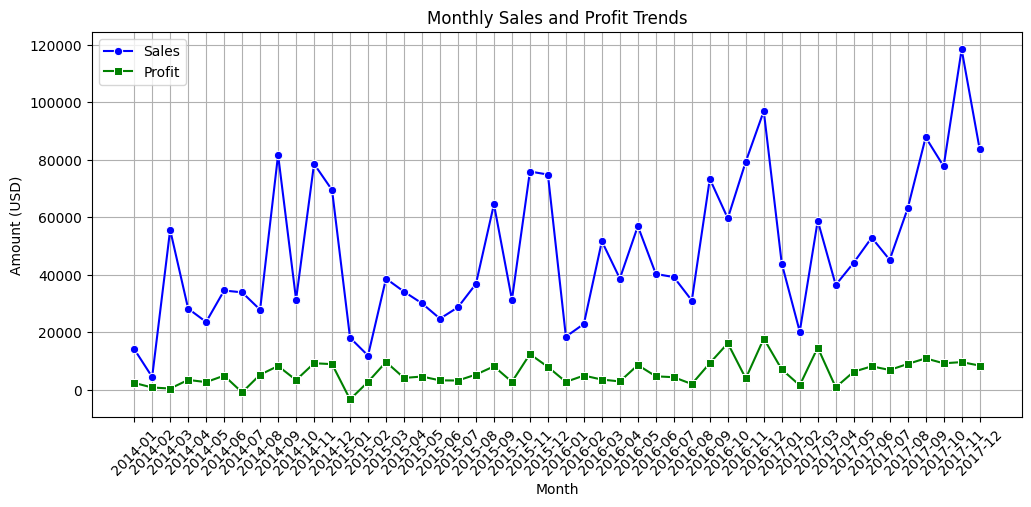

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a sales trend plot
plt.figure(figsize=(12, 5))
sns.lineplot(x=monthly_sales['YearMonth'].astype(str), y=monthly_sales['Sales'], marker='o', color='b', label="Sales")
sns.lineplot(x=monthly_sales['YearMonth'].astype(str), y=monthly_sales['Profit'], marker='s', color='g', label="Profit")

plt.xticks(rotation=45)
plt.title("Monthly Sales and Profit Trends")
plt.xlabel("Month")
plt.ylabel("Amount (USD)")
plt.legend()
plt.grid()

# Save the visualization
plot_path = "Sales.png"
plt.savefig(plot_path)
plt.show()

## Generate a summary of key insights

In [10]:
# Generate summary insights
sales_trend = f"""
Total Sales: ${monthly_sales['Sales'].sum():,.2f}
Total Profit: ${monthly_sales['Profit'].sum():,.2f}
Highest Sales Month: {monthly_sales.loc[monthly_sales['Sales'].idxmax(), 'YearMonth']}
Lowest Sales Month: {monthly_sales.loc[monthly_sales['Sales'].idxmin(), 'YearMonth']}
Highest Profit Month: {monthly_sales.loc[monthly_sales['Profit'].idxmax(), 'YearMonth']}
Lowest Profit Month: {monthly_sales.loc[monthly_sales['Profit'].idxmin(), 'YearMonth']}
"""

print(sales_trend)


Total Sales: $2,297,201.07
Total Profit: $286,397.79
Highest Sales Month: 2017-11
Lowest Sales Month: 2014-02
Highest Profit Month: 2016-12
Lowest Profit Month: 2015-01



## Generate a pdf report

In [11]:
!pip install fpdf

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 24.3.1 -> 25.0.1
[notice] To update, run: C:\Users\hp\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [14]:
from fpdf import FPDF

# Create PDF object
pdf = FPDF()
pdf.set_auto_page_break(auto=True, margin=15)
pdf.add_page()
pdf.set_font("Arial", size=12)

# Add title
pdf.cell(200, 10, "Automated Sales Report", ln=True, align='C')
pdf.ln(10)

# Add summary text
pdf.multi_cell(0, 10, sales_trend)
pdf.ln(10)

# Add visualization
pdf.image(plot_path, x=10, y=None, w=180)

# Save the PDF
pdf_path = "Sales_Report.pdf"
pdf.output(pdf_path)

print("Report generated successfully!")

Report generated successfully!
